In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Q1. Dataset Exploration

In [3]:
df = pd.read_csv('/content/Attrition.csv')

In [4]:
df.head(10)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
5,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,...,3,80,0,8,2,2,7,7,3,6
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,...,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,...,2,80,1,1,2,3,1,0,0,0
8,38,No,Travel_Frequently,216,Research & Development,23,3,Life Sciences,1,12,...,2,80,0,10,2,3,9,7,1,8
9,36,No,Travel_Rarely,1299,Research & Development,27,3,Medical,1,13,...,2,80,2,17,3,2,7,7,7,7


In [5]:
df.tail(5)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


In [6]:
print("Total number of rows and columns:", df.shape)

Total number of rows and columns: (1470, 35)


In [7]:
print('All column names:', df.columns)

All column names: Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')


In [8]:
print('The data types of all columns:', df.dtypes)

The data types of all columns: Age                          int64
Attrition                   object
BusinessTravel              object
DailyRate                    int64
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EmployeeCount                int64
EmployeeNumber               int64
EnvironmentSatisfaction      int64
Gender                      object
HourlyRate                   int64
JobInvolvement               int64
JobLevel                     int64
JobRole                     object
JobSatisfaction              int64
MaritalStatus               object
MonthlyIncome                int64
MonthlyRate                  int64
NumCompaniesWorked           int64
Over18                      object
OverTime                    object
PercentSalaryHike            int64
PerformanceRating            int64
RelationshipSatisfaction     int64
StandardHours                int64
StockOptionLevel        

Q2. Data Quality Check

In [9]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [10]:
print('Duplicate Records Exist:',df.duplicated().any())

Duplicate Records Exist: False


In [11]:
print('Duplicate Records:',df.duplicated().sum())

Duplicate Records: 0


In [12]:
print('Total Number of Duplicate Records:',df.duplicated().sum())

Total Number of Duplicate Records: 0


In [20]:
# Find the total number of employees in each department.
emp_dep = df.groupby('Department')['EmployeeNumber'].count()
print(emp_dep)

Department
Human Resources            63
Research & Development    961
Sales                     446
Name: EmployeeNumber, dtype: int64


In [23]:
# Find which department has the maximum number of employees.
max_emp_dep = emp_dep.idxmax()
print(max_emp_dep)

Research & Development


In [25]:
# Display the department-wise employee count in descending order.
emp_dep_desc = emp_dep.sort_values(ascending=False)
print(emp_dep_desc)

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: EmployeeNumber, dtype: int64


In [26]:
# Calculate the average monthly income of all employees.
avg_income = df['MonthlyIncome'].mean()
print(avg_income)

6502.931292517007


In [27]:
# Find the maximum and minimum monthly income.
max_income = df['MonthlyIncome'].max()
min_income = df['MonthlyIncome'].min()
print(max_income)
print(min_income)

19999
1009


In [28]:
median_income = df['MonthlyIncome'].median()
print(median_income)

4919.0


•	Calculate the average monthly income department-wise.

In [30]:
avg_income_dept = df.groupby('Department')['MonthlyIncome'].mean()
print(avg_income_dept)

Department
Human Resources           6654.507937
Research & Development    6281.252862
Sales                     6959.172646
Name: MonthlyIncome, dtype: float64


•	Find the average age of employees

In [31]:
avg_age = df['Age'].mean()
print(avg_age)

36.923809523809524


•	Find the maximum and minimum age.

In [32]:
max_age = df['Age'].max()
min_age = df['Age'].min()
print(max_age)
print(min_age)


60
18


•	Calculate the average years of experience (TotalWorkingYears)

In [33]:
avg_year = df['TotalWorkingYears'].mean()
print(avg_year)


11.279591836734694


•	Find the average YearsAtCompany for employees

In [34]:
avg_yearatcompany = df['YearsAtCompany'].mean()
print(avg_yearatcompany)

7.0081632653061225


Q6. Bar Chart – Department Analysis

•	Create a bar chart showing the number of employees working in each department.
•	X-axis: Department.
•	Y-axis: Number of employees.
•	Add a suitable chart title.
•	Display values on top of the bars.


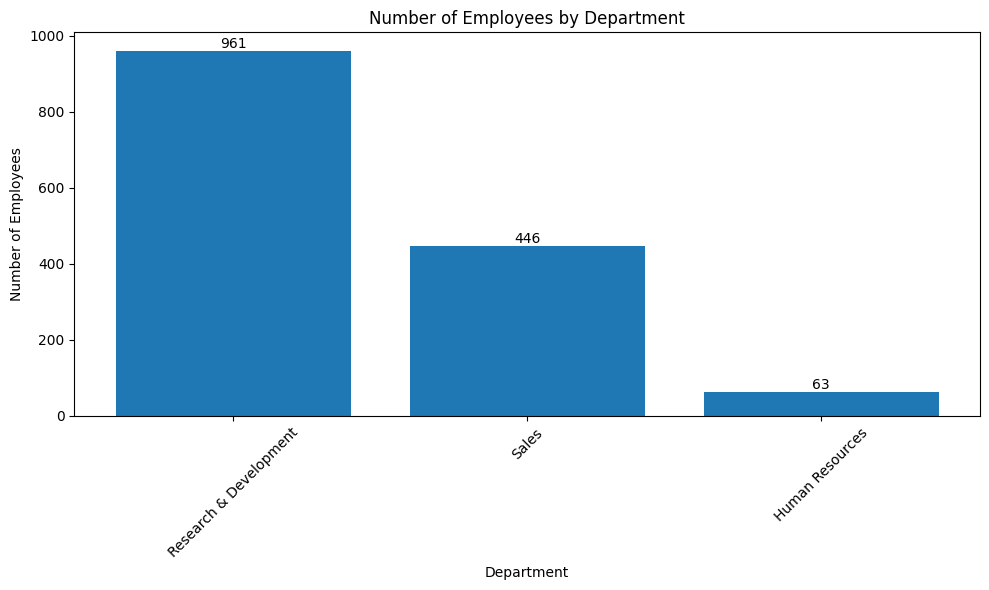

In [36]:
dept_count = df['Department'].value_counts()

# Create bar chart
plt.figure(figsize=(10, 6))
bars = plt.bar(dept_count.index, dept_count.values)

# Add values on top of bars
plt.bar_label(bars)

# Add chart title and axis labels
plt.title('Number of Employees by Department')
plt.xlabel('Department')
plt.ylabel('Number of Employees')

# Improve layout
plt.xticks(rotation=45)
plt.tight_layout()

# Display chart
plt.show()

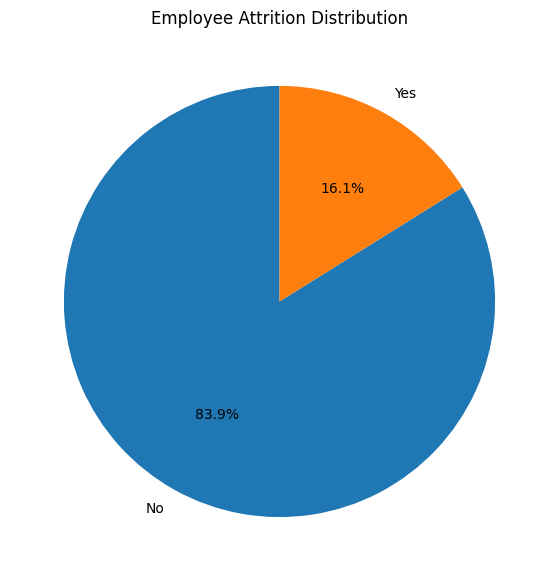

In [37]:
attrition_count = df['Attrition'].value_counts()

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    attrition_count,
    labels=attrition_count.index,
    autopct='%1.1f%%',
    startangle=90
)

# Add chart title
plt.title('Employee Attrition Distribution')

# Display chart
plt.show()

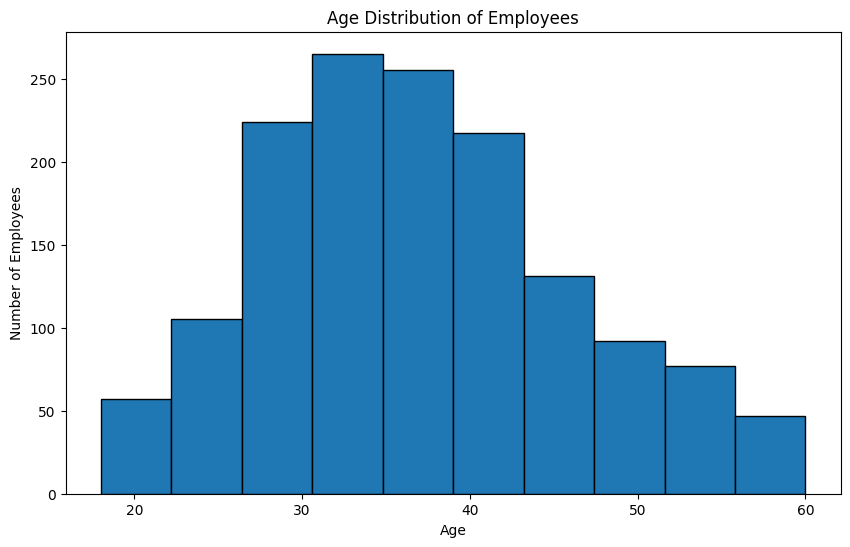

In [38]:

# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(df['Age'], bins=10, edgecolor='black')

# Add title and labels
plt.title('Age Distribution of Employees')
plt.xlabel('Age')
plt.ylabel('Number of Employees')

# Display chart
plt.show()

In [39]:
counts, bins = np.histogram(df['Age'], bins=10)

max_bin = counts.argmax()

print("Highest employee count:", counts[max_bin])

print("Age range:",
      bins[max_bin],
      "to",
      bins[max_bin + 1])

Highest employee count: 265
Age range: 30.6 to 34.8


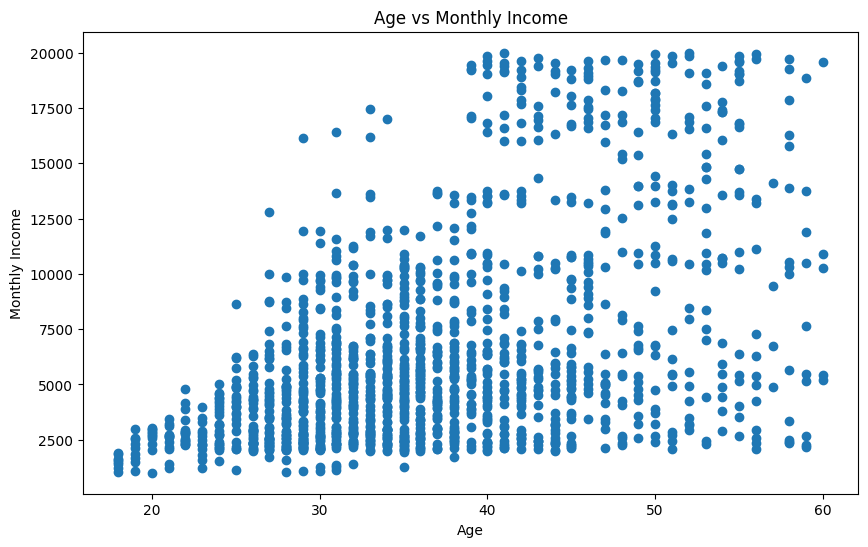

In [40]:
# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(df['Age'], df['MonthlyIncome'])

# Add title and labels
plt.title('Age vs Monthly Income')
plt.xlabel('Age')
plt.ylabel('Monthly Income')

# Display chart
plt.show()

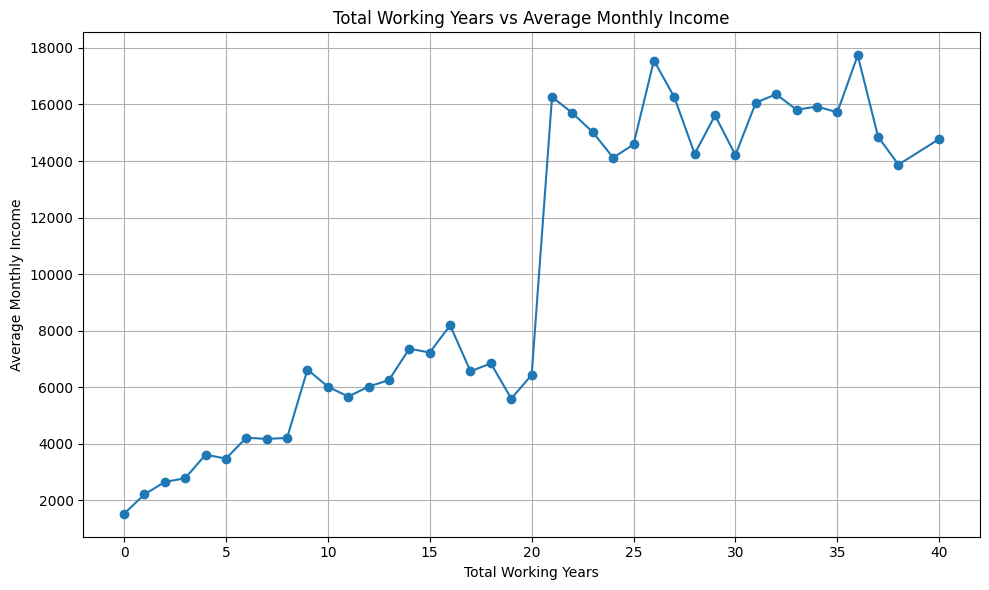

In [41]:
# Group employees by TotalWorkingYears
# Calculate average MonthlyIncome
experience_income = df.groupby('TotalWorkingYears')['MonthlyIncome'].mean()

# Create line chart
plt.figure(figsize=(10, 6))

plt.plot(
    experience_income.index,
    experience_income.values,
    marker='o',
    linestyle='-'
)

# Add title and labels
plt.title('Total Working Years vs Average Monthly Income')
plt.xlabel('Total Working Years')
plt.ylabel('Average Monthly Income')

# Display chart
plt.grid(True)
plt.tight_layout()
plt.show()

Attrition                No  Yes
Department                      
Human Resources          51   12
Research & Development  828  133
Sales                   354   92


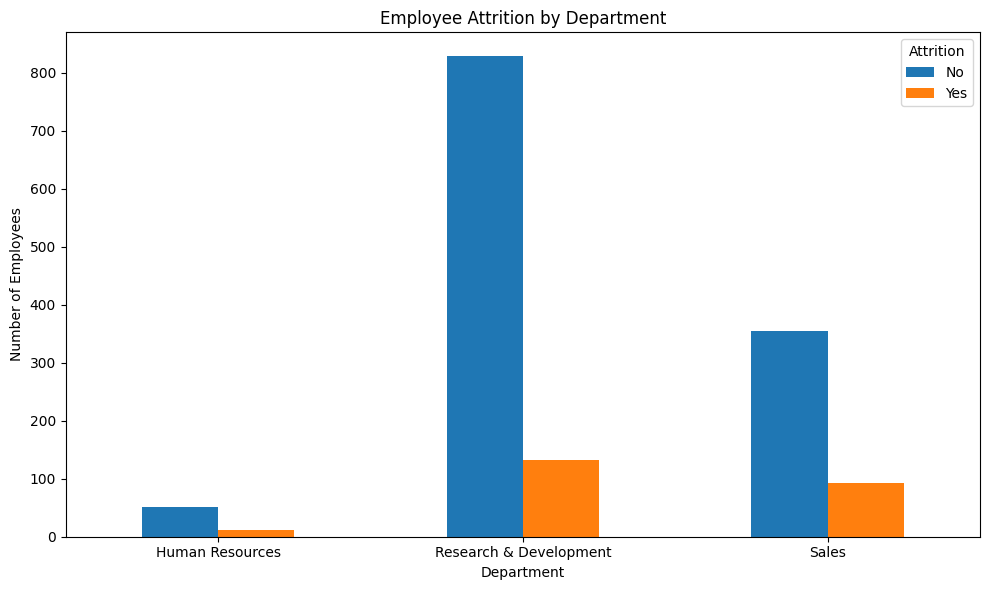

In [42]:
# Group data by Department and Attrition
dept_attrition = df.groupby(
    ['Department', 'Attrition']
).size().unstack()

print(dept_attrition)

# Create bar chart
dept_attrition.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Employee Attrition by Department')
plt.xlabel('Department')
plt.ylabel('Number of Employees')

plt.xticks(rotation=0)
plt.legend(title='Attrition')
plt.tight_layout()
plt.show()

Gender Count:
Gender
Male      882
Female    588
Name: count, dtype: int64

Gender Percentage:
Gender
Male      60.0
Female    40.0
Name: proportion, dtype: float64


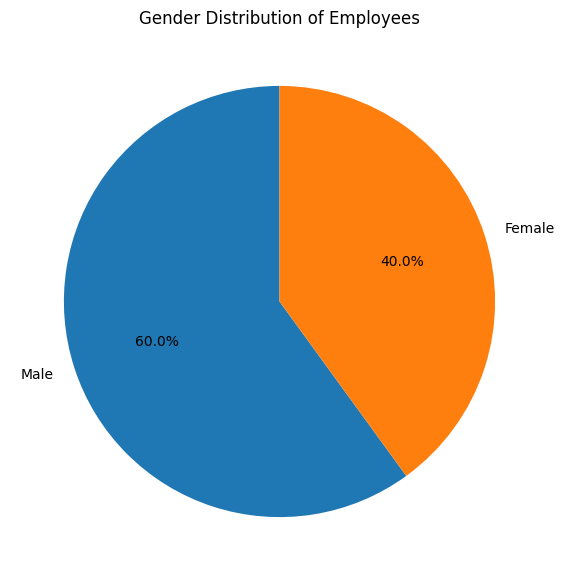

In [43]:
# Count male and female employees
gender_count = df['Gender'].value_counts()

# Calculate percentage
gender_percentage = df['Gender'].value_counts(
    normalize=True
) * 100

print("Gender Count:")
print(gender_count)

print("\nGender Percentage:")
print(gender_percentage)

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    gender_count,
    labels=gender_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Gender Distribution of Employees')

plt.show()

In [44]:
# Count employees in each overtime category
overtime_count = df['OverTime'].value_counts()

print("Overtime Employee Count:")
print(overtime_count)

# Group by OverTime and Attrition
overtime_attrition = df.groupby(
    'OverTime'
)['Attrition'].value_counts().unstack()

print("\nOvertime Attrition:")
print(overtime_attrition)

# Calculate attrition percentage
attrition_percentage = (
    overtime_attrition['Yes'] /
    overtime_attrition.sum(axis=1)
) * 100

print("\nAttrition Percentage:")
print(attrition_percentage)

Overtime Employee Count:
OverTime
No     1054
Yes     416
Name: count, dtype: int64

Overtime Attrition:
Attrition   No  Yes
OverTime           
No         944  110
Yes        289  127

Attrition Percentage:
OverTime
No     10.436433
Yes    30.528846
dtype: float64


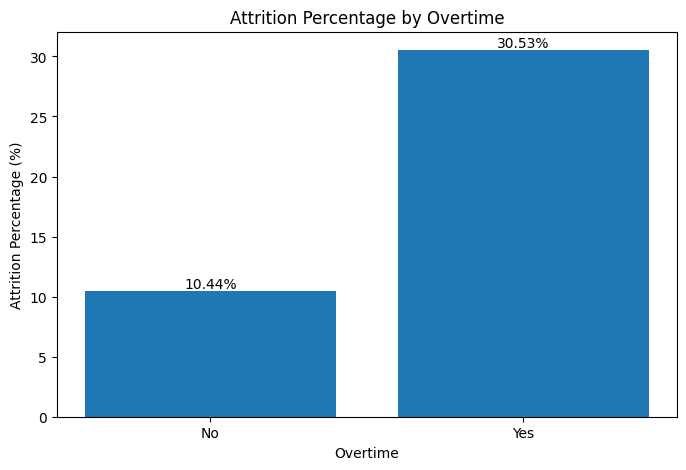

In [45]:
# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    attrition_percentage.index,
    attrition_percentage.values
)

# Display percentage values
plt.bar_label(bars, fmt='%.2f%%')

plt.title('Attrition Percentage by Overtime')
plt.xlabel('Overtime')
plt.ylabel('Attrition Percentage (%)')

plt.show()

In [46]:
avg_satisfaction = df['JobSatisfaction'].mean()

print("Average Job Satisfaction:", avg_satisfaction)

Average Job Satisfaction: 2.7285714285714286


In [47]:
satisfaction_count = df['JobSatisfaction'].value_counts().sort_index()

print("Employee Satisfaction Count:")
print(satisfaction_count)

Employee Satisfaction Count:
JobSatisfaction
1    289
2    280
3    442
4    459
Name: count, dtype: int64


In [48]:
most_common = satisfaction_count.idxmax()

print("Most Common Satisfaction Score:", most_common)

Most Common Satisfaction Score: 4


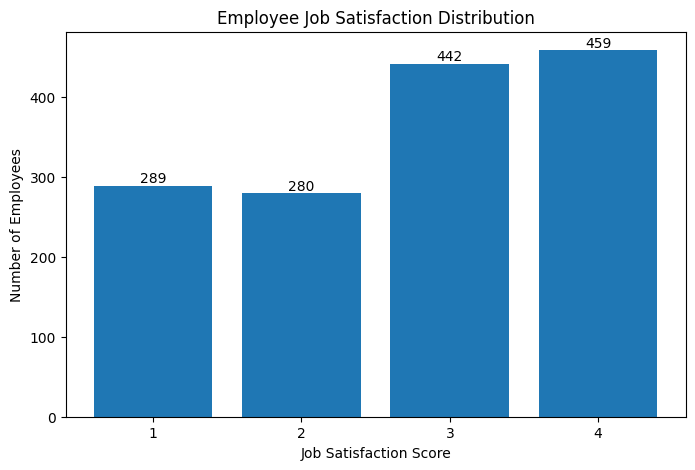

In [50]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    satisfaction_count.index,
    satisfaction_count.values
)

plt.bar_label(bars)

plt.title('Employee Job Satisfaction Distribution')
plt.xlabel('Job Satisfaction Score')
plt.ylabel('Number of Employees')

plt.xticks([1, 2, 3, 4])

plt.show()

In [51]:
# Group employees by department
dept_salary = df.groupby('Department')['MonthlyIncome'].mean()

print("Average Monthly Income by Department:")
print(dept_salary)

Average Monthly Income by Department:
Department
Human Resources           6654.507937
Research & Development    6281.252862
Sales                     6959.172646
Name: MonthlyIncome, dtype: float64


In [52]:
highest_salary_dept = dept_salary.idxmax()

highest_salary = dept_salary.max()

print("Highest Salary Department:", highest_salary_dept)

print("Highest Average Salary:", highest_salary)

Highest Salary Department: Sales
Highest Average Salary: 6959.17264573991


In [53]:
lowest_salary_dept = dept_salary.idxmin()

lowest_salary = dept_salary.min()

print("Lowest Salary Department:", lowest_salary_dept)

print("Lowest Average Salary:", lowest_salary)

Lowest Salary Department: Research & Development
Lowest Average Salary: 6281.252861602497


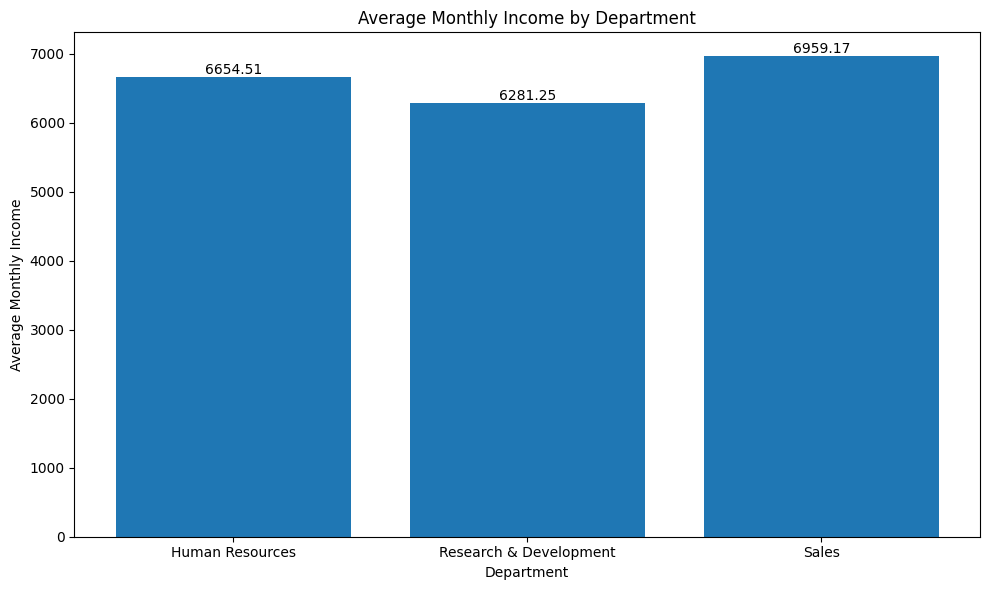

In [54]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    dept_salary.index,
    dept_salary.values
)

# Display salary values
plt.bar_label(bars, fmt='%.2f')

plt.title('Average Monthly Income by Department')
plt.xlabel('Department')
plt.ylabel('Average Monthly Income')

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()